In [ ]:
import pandas as pd
from tqdm.auto import tqdm
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba

from scipy.stats import norm

tqdm.pandas()

/Users/tylergarfield/miniconda3/envs/stat5000_final_proj_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Load the data

In [2]:
spotify_tracks = pd.read_csv('spotify_tracks_pop.csv')
display(pd.read_csv('spotify_tracks_pop.csv').head(5))
spotify_tracks['track_album_release_date'] = pd.to_datetime(spotify_tracks['track_album_release_date'])
spotify_tracks['track_album_year'] = spotify_tracks['track_album_release_date'].dt.year
spotify_tracks.shape

,id,energy,tempo,danceability,loudness,liveness,valence,time_signature,speechiness,track_album_release_date,...,duration_min,acousticness,num_artists,first_listed_artist,track_album_name,playlist_name,playlist_genre,playlist_subgenre,track_name,track_popularity
0,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,4.194467,0.3080,2,Lady Gaga,Die With A Smile,Today's Top Hits,pop,mainstream,Die With A Smile,100
1,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,4.194467,0.3080,2,Lady Gaga,Die With A Smile,Global Top 50,pop,global,Die With A Smile,100
2,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,4.194467,0.3080,2,Lady Gaga,Die With A Smile,Top Gaming Tracks,gaming,modern,Die With A Smile,100
3,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4/4,0.2600,2024-10-18,...,2.831950,0.0283,2,ROSÉ,APT.,Today's Top Hits,pop,mainstream,APT.,98
4,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4/4,0.2600,2024-10-18,...,2.831950,0.0283,2,ROSÉ,APT.,Global Top 50,pop,global,APT.,98


(4684, 24)

In [3]:
spotify_tracks.dtypes

id                                     str
energy                             float64
tempo                              float64
danceability                       float64
loudness                           float64
liveness                           float64
valence                            float64
time_signature                         str
speechiness                        float64
track_album_release_date    datetime64[us]
instrumentalness                   float64
mode                                   str
key                                float64
duration_min                       float64
acousticness                       float64
num_artists                          int64
first_listed_artist                    str
track_album_name                       str
playlist_name                          str
playlist_genre                         str
playlist_subgenre                      str
track_name                             str
track_popularity                     int64
track_album

# Next we'll use quantile binning to actually assign bin labels in a more robust manner.

In [4]:
spotify_tracks['Track Popularity Class'] = pd.qcut(spotify_tracks['track_popularity'],q=3,labels=['low','medium','high'])
spotify_tracks['Track Popularity Class']

0       high
1       high
2       high
3       high
4       high
        ... 
4679     low
4680     low
4681     low
4682     low
4683     low
Name: Track Popularity Class, Length: 4684, dtype: category
Categories (3, str): ['low' < 'medium' < 'high']

# Using bootstrapping for mean confidence intervals of loudness per track popularity levels across years.

So the first thing we need to do is determine which years even have enough points in all three popularity tears to perform bootstrapping on. If a year has 0 or only 2 tracks that fall into the low popularity bin, for example, then we cannot make any assumptions about that sample of two representing the overall population. Since the minimum sample size for a z-critical confidence interval we were given in class was n>= 30 the decision was made to ensure the group sizes we were bootstrapping from were at least half that. NOTE the CLT only applies to the sample mean distribution, and we are doing confidence intervals for the median here. So, we would have never used a z-critical confidence interval no matter how large our sample size was because we are not doing a CI for the median, the n>= 15 was chosen merely to have variety in the bootstrapped samples we are using.

In [5]:
# Determine for each year popularity level combo how many records fall into that category.
track_pop_by_year = spotify_tracks.groupby(by=['track_album_year','Track Popularity Class'])['id'].agg(['count']).reset_index().sort_values(by='track_album_year')
# Make sure we retain only year popularity level combos that have at least 15 records.
track_pop_by_year = track_pop_by_year[track_pop_by_year['count'] >= 15]
track_pop_by_year = track_pop_by_year.sort_values(by=['track_album_year','Track Popularity Class'])

years_with_high_med_low = []

# Now get all the years that after the above pruning still have all three popularity levels represented.
for year in track_pop_by_year['track_album_year'].unique():
    if len(track_pop_by_year[track_pop_by_year['track_album_year'] == year]['Track Popularity Class'].unique()) == 3:
        years_with_high_med_low.append(int(year))


Now the cell bellow actually performs the bootstrapped confidence interval by year and popularity level.

In [147]:
# First retain only the data for the years that have enough records according to the selection process above.
year_loudness_comp = spotify_tracks[spotify_tracks['track_album_year'].isin(years_with_high_med_low)]

# Set the seed for reproducibility
np.random.seed(42)



# This array will hold the final results and then be turned into the data frame used to make the visuals.
median_loudness_by_year = []

# Get a single bootstrapped sample the same size as the original vector. And then
# compute the median of that sample.
def get_bootstrapped_sample(loudness_np,n):

    
    rand_samp = np.random.choice(loudness_np,size=n,replace=True)

    return np.median(rand_samp)

# Now for each popularity level run through each year and perform the bootstrapping process on that year.
for pop_lev in year_loudness_comp['Track Popularity Class'].unique():

    # First filter to only the current popularity level.
    tracks_for_pop = year_loudness_comp[year_loudness_comp['Track Popularity Class'] == pop_lev].copy()

    # Next we will calculate all the years median loudness for the current popularity level.
    tracks_for_pop_med_by_year = tracks_for_pop.groupby(by='track_album_year')['loudness'].agg(['median']).reset_index().sort_values(by='track_album_year')

    # Now for each year we will construct the bootstrapped median confidence interval.
    for year in year_loudness_comp['track_album_year'].unique():

        # Set B or the number of bootstrapped samples to be pretty large for maximizing result stability.
        B = 10000

        # Now get all the loudness values for the current year and popularity level as a numpy array.
        pop_lev_curr_year_curr = tracks_for_pop[tracks_for_pop['track_album_year'] == year]['loudness'].to_numpy()

        # Get the original size of each of our resamples.
        n = pop_lev_curr_year_curr.shape[0]

        # Now using list comprehension and the above method construct a vector of x~* median values of
        # length B.
        bootstrapped_samps = [get_bootstrapped_sample(pop_lev_curr_year_curr,n) for _ in range(B)]

        # Here 95% confidence interval is used 
        alpha = 0.05 # 95%

        # Now get the upper and lower bounds of the bootstrapped confidence interval.
        CI_L = np.percentile(bootstrapped_samps, (alpha/2)*100)   
        CI_U = np.percentile(bootstrapped_samps, (1-alpha/2)*100)  

        # Now append the current result to the results list.
        median_loudness_by_year.append([int(year),pop_lev,tracks_for_pop_med_by_year[(tracks_for_pop_med_by_year['track_album_year'] == year)].reset_index().at[0,'median'],CI_L,CI_U])

# Now make the results list into a data frame for plotting.
median_loudness_by_year = pd.DataFrame(median_loudness_by_year,columns=['year','pop_lev','med_loud','CI_L','CI_U'])
# Get the frame sorted also for plotting later.
median_loudness_by_year = median_loudness_by_year.sort_values(by=['year','pop_lev'],ascending=True)
# Change the year to a string so that it will be recognized as categorical on the plot.
median_loudness_by_year['year'] = median_loudness_by_year['year'].apply(lambda x: str(x))

# Also calc CI width for plot bellow.
def calc_ci_width(row):
    return row['CI_U'] - row['CI_L']

median_loudness_by_year['CI_Width'] = median_loudness_by_year.apply(calc_ci_width,axis=1)

Now plot the resulting confidence intervals.

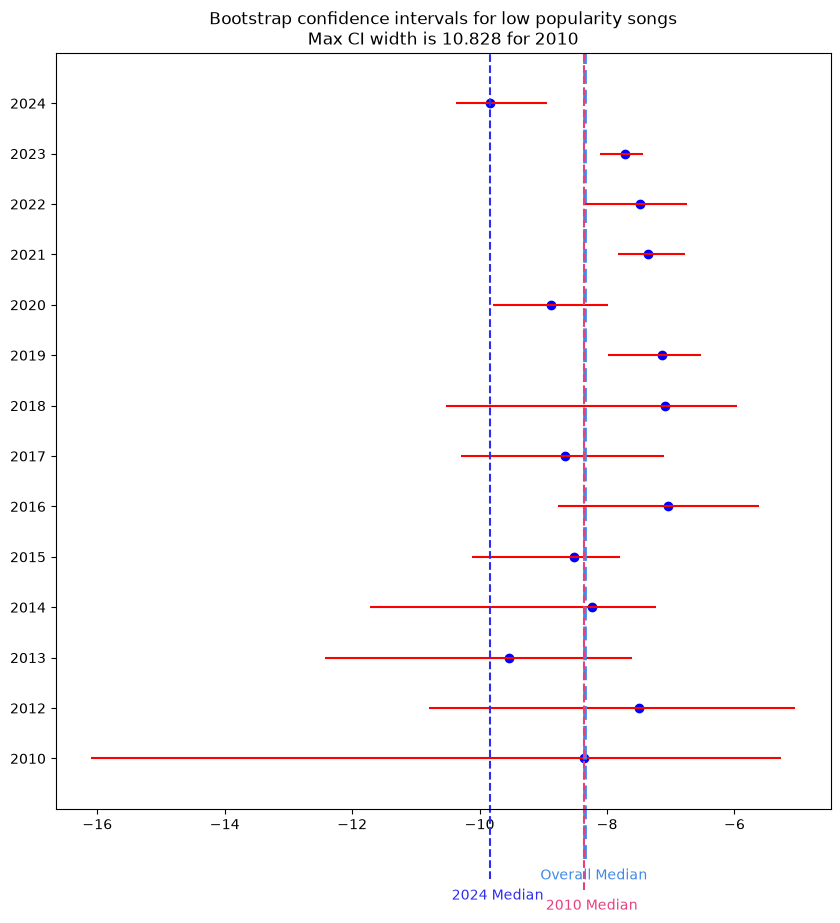

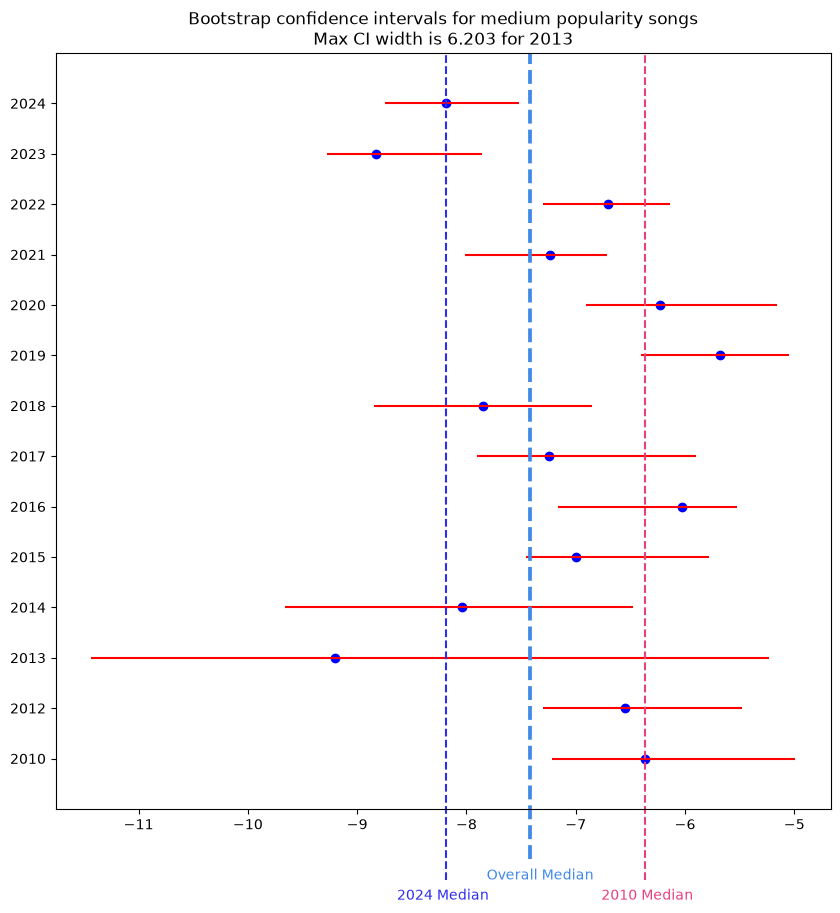

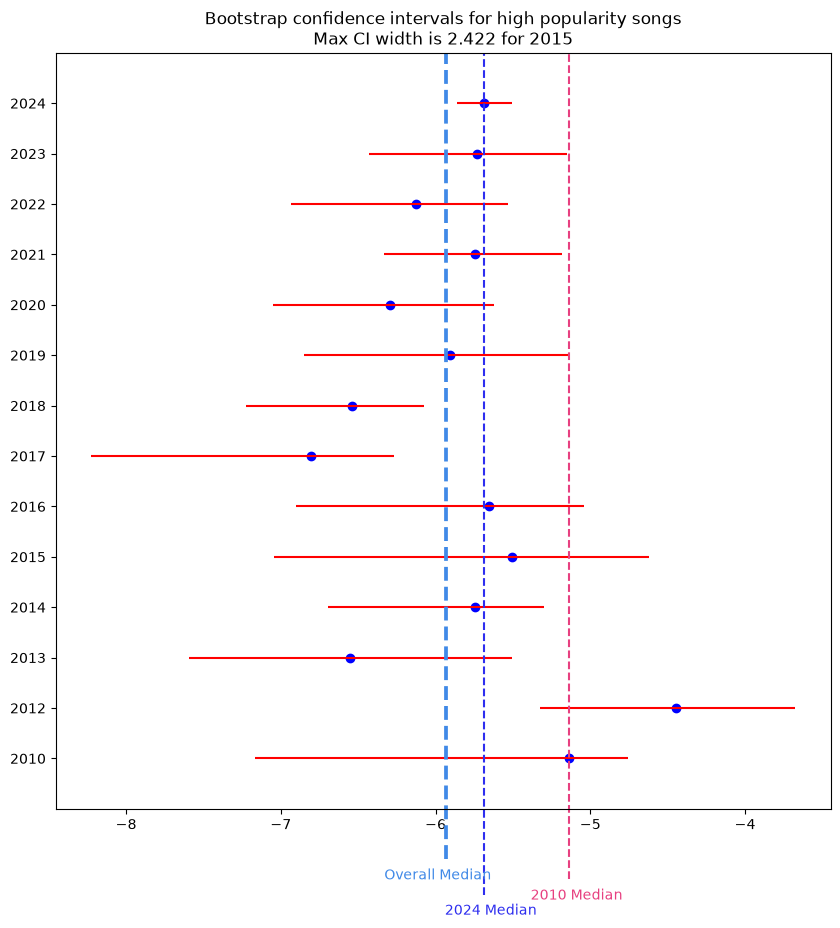

In [165]:

annot_overall_med_offsets = [0.7,0.4,0.4]

annot_offsets_x_2024_med = [0.6,0.45,0.25]
annot_offsets_y_2024_med = [2.8,2.8,3.1]

annot_offsets_x_2010_med = [0.6,0.4,0.25]
annot_offsets_y_2010_med = [3.0,2.8,2.8]

# Now for each confidence level plot the bootstrapped CI's for each year
for lev_idx,pop_lev in enumerate(['low','medium','high']):

    # reset the current plot.
    fig, ax = plt.subplots(figsize=(10,12))
    fig.subplots_adjust(bottom=0.25)
    

    # Get the overall median loudness for the current popularity bucket.
    med_for_pop_lev = spotify_tracks[spotify_tracks['Track Popularity Class'] == pop_lev]['loudness'].median()


    ytick_vals = np.arange(0,len(years_with_high_med_low ))
    year_labs = []

    # Also get max confidence interval width 
    only_pop_lev_curr = median_loudness_by_year[median_loudness_by_year['pop_lev'] == pop_lev].copy()
    max_width_pop_lev_curr = only_pop_lev_curr['CI_Width'].max()
    year_with_max_width_popcurr = only_pop_lev_curr.loc[(only_pop_lev_curr['CI_Width'] == max_width_pop_lev_curr),'year'].iloc[0]


    # Now for each year and the current popularity value plot its confidence interval.
    for idx, year in enumerate(years_with_high_med_low):
        med_curr = median_loudness_by_year[(median_loudness_by_year['pop_lev'] == pop_lev) & (median_loudness_by_year['year'] == str(year))]['med_loud'].iloc[0]
        lb_curr = median_loudness_by_year[(median_loudness_by_year['pop_lev'] == pop_lev) & (median_loudness_by_year['year'] == str(year))]['CI_L'].iloc[0]
        ub_curr = median_loudness_by_year[(median_loudness_by_year['pop_lev'] == pop_lev) & (median_loudness_by_year['year'] == str(year))]['CI_U'].iloc[0]


        ax.scatter(x = med_curr,y=ytick_vals[idx],color="blue")
        ax.hlines(y=ytick_vals[idx],xmin=lb_curr,xmax=ub_curr,color="red")

        

        year_labs.append(years_with_high_med_low[idx])

    # I also want to draw a line for comparison of the 2024 and 2010 median popularity.
    med_2024 = median_loudness_by_year[(median_loudness_by_year['pop_lev'] == pop_lev) & (median_loudness_by_year['year'] == '2024')]['med_loud'].iloc[0]
    med_2010 = median_loudness_by_year[(median_loudness_by_year['pop_lev'] == pop_lev) & (median_loudness_by_year['year'] == '2010')]['med_loud'].iloc[0]

    ax.set_title(f"Bootstrap confidence intervals for {pop_lev} popularity songs\nMax CI width is {max_width_pop_lev_curr:.3f} for {year_with_max_width_popcurr}")


    ax.vlines(med_for_pop_lev,min(ytick_vals)-2,max(ytick_vals)+1,linestyles='dashed',clip_on=False,color="#4089e7",linewidth=2.7)

    ax.annotate(text=f"Overall Median",xy=(med_for_pop_lev-annot_overall_med_offsets[lev_idx],min(ytick_vals)-2.4),annotation_clip=False,color="#4089e7")

    
    ax.vlines(med_2024,min(ytick_vals)-(annot_offsets_y_2024_med[lev_idx]-0.4),max(ytick_vals)+1,linestyles='dashed',clip_on=False,color="#2e2eef")
    ax.annotate(text=f"2024 Median",xy=(med_2024-annot_offsets_x_2024_med[lev_idx],min(ytick_vals)-annot_offsets_y_2024_med[lev_idx]),annotation_clip=False,color="#2e2eef")
    ax.vlines(med_2010,min(ytick_vals)-(annot_offsets_y_2010_med[lev_idx]-0.4),max(ytick_vals)+1,linestyles='dashed',clip_on=False,color="#e74080")
    ax.annotate(text=f"2010 Median",xy=(med_2010-annot_offsets_x_2010_med[lev_idx],min(ytick_vals)-annot_offsets_y_2010_med[lev_idx]),annotation_clip=False,color="#e74080")


    ax.set_ylim(min(ytick_vals)-1,max(ytick_vals)+1)
    ax.set_yticks(ytick_vals,year_labs)
    ax.set_yticklabels(year_labs)
        
    plt.show()

Results of note here: First, the overall median loudness value shifts to the left or louder going from low to high popularity songs. Second, for all the popularity levels the observed median values for the sample for the 2024 subset is louder (a closer db to zero) than the 2010 subset. HOWEVER, there is one important caveat to this, for both high and low popularity songs our 2010 bootstrap CI is pretty large (2 db for the high pop songs and 10 db for the low pop songs) and therefore does cross the threshold of where the 2010 songs could have a higher median loudness for the high and low pop subsets compared to the 2024 CI. Interestingly too, as we move through the increasing popularity levels the confidence largest confidence interval width shrinks by about 8.406; a pretty significant amount. So overall our observed medians for all years for each popularity bin seem to reliably increase and the observed medians for all popularity levels from 2010 to 2024 seem to show a increase towards the louder end of the spectrum. The important cavitate is that the observed confidence interval for this particular experiment setup 2010 low popularity songs covers nearly the whole range of the graph, and in every popularity level but medium the 2010 and 2024 confidence intervals to do overlap.